In [1]:
!python tools/test.py --weights weights/End-to-end.pth

/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:644: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
=> creating runs/BddDataset/_2026-02-04-07-26
Namespace(modelDir='', logDir='runs/', weights=['weights/End-to-end.pth'], conf_thres=0.001, iou_thres=0.6)
AUTO_RESUME: False
CUDNN:
  BENCHMARK: True
  DETERMINISTIC: False
  ENABLED: True
DATASET:
  COLOR_RGB: False
  DATAROOT: /workspace/dataset/images
  DATASET: BddDataset
  DATA_FORMAT: jpg
  FLIP: True
  HSV_H: 0.015
  HSV_S: 0.7
  HSV_V: 0.4
  LABELROOT: /workspace/dataset/det_annotations
  LANEROOT: /workspace/dataset/ll_seg_annotations
  MASKROOT: /workspace/dataset/da_seg_annotations
  ORG_IMG_SIZE: [720, 1280]
  ROT_FACTOR: 10
  SCALE_FACTOR: 0.25
  SELECT_DATA: False
  SHEAR: 0.0
  TEST_SET: val
  TRAIN_SET: train
  TRANSLATE: 0.1
DEBUG: False
GPUS: (0,)
LOG_DIR: runs/
LOSS:
  BOX_GAIN: 0.05
  CLS_GAIN: 0.5
  CLS_POS_WEIGHT: 1.0
  DA_SEG_GAIN: 0.2
  FL_GAMMA: 0.0
  LL_IOU_GAIN: 0.2
  LL

/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:644: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


 Chargement du modèle sur cpu...
 Modèle chargé.
🚀 Traitement : dataset/images/val/b1c66a42-6f7d68ca.jpg


/usr/local/lib/python3.10/dist-packages/torch/functional.py:512: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /opt/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:3559.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


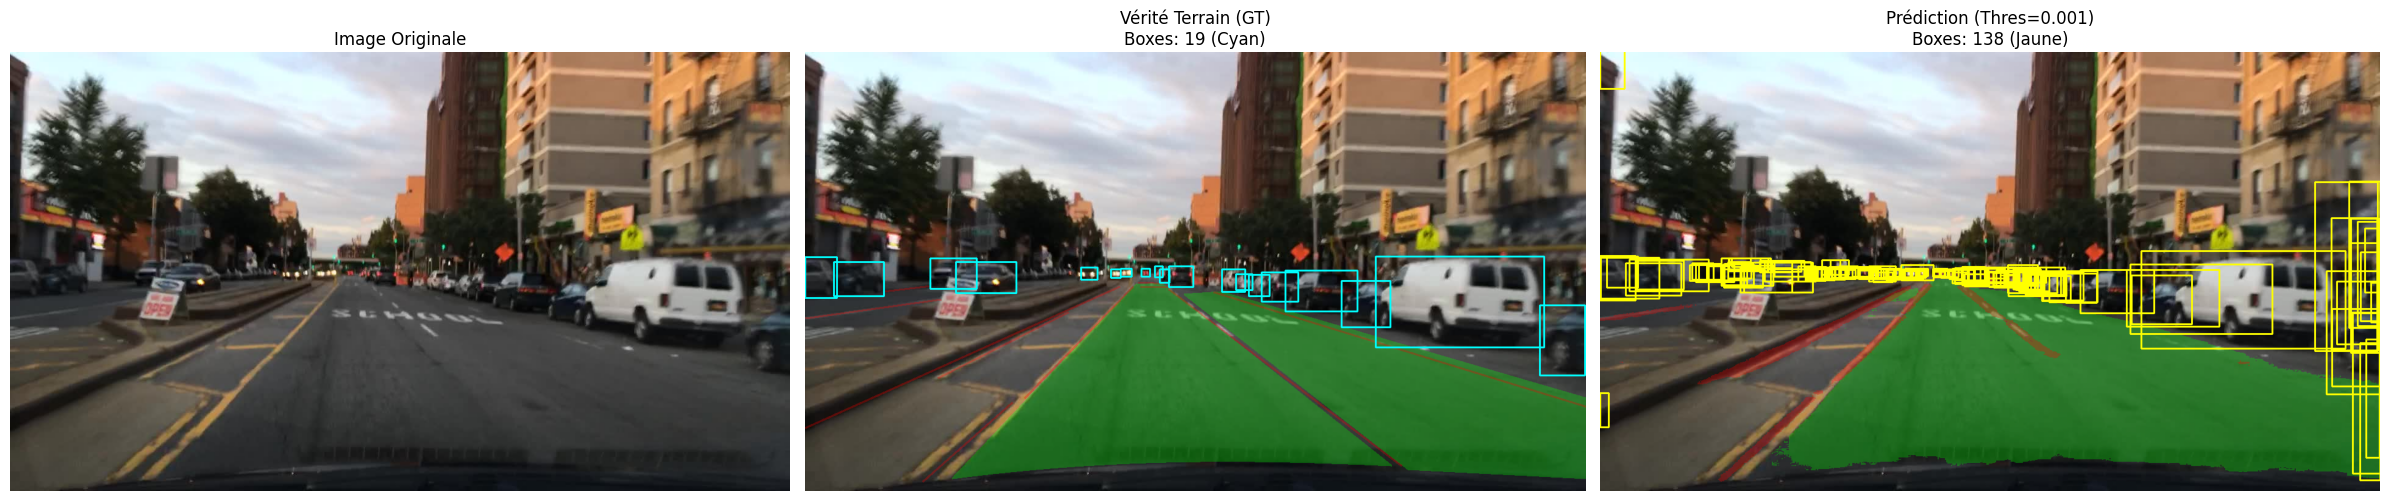

 Terminé !


In [2]:
# %% [CODE COMPLET : 3 VUES + THRESHOLD 0.001]
import os
import sys
import cv2
import json
import torch
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.getcwd())
from lib.config import cfg
from lib.models import get_net
from lib.core.general import non_max_suppression

IMG_PATH = "dataset/images/val/b1c66a42-6f7d68ca.jpg" 
WEIGHTS_PATH = "weights/End-to-end.pth" 
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

cfg.merge_from_list(["MODEL.IMAGE_SIZE", [640, 640]])

if not os.path.exists(WEIGHTS_PATH): raise FileNotFoundError(f"Poids absents: {WEIGHTS_PATH}")
print(f" Chargement du modèle sur {device}...")
model = get_net(cfg)
checkpoint = torch.load(WEIGHTS_PATH, map_location=device)
model.load_state_dict(checkpoint['state_dict'])
model = model.to(device).eval()
print(" Modèle chargé.")

def infer_image(img_path):
    if not os.path.exists(img_path): raise FileNotFoundError(f"Image introuvable: {img_path}")
    img_bgr = cv2.imread(img_path)
    h_orig, w_orig = img_bgr.shape[:2]
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    img_resized = cv2.resize(img_rgb, (640, 640))
    img_norm = (img_resized.astype(np.float32) / 255.0 - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
    img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).float().to(device)

    with torch.no_grad():
        det_out, da_seg_out, ll_seg_out = model(img_tensor)

    _, da_lbl = torch.max(da_seg_out, 1)
    _, ll_lbl = torch.max(ll_seg_out, 1)
    da_mask = cv2.resize(da_lbl.squeeze().cpu().numpy().astype(np.uint8), (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
    ll_mask = cv2.resize(ll_lbl.squeeze().cpu().numpy().astype(np.uint8), (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)

    preds = det_out[0] if isinstance(det_out, (tuple, list)) else det_out
    
    nms_preds = non_max_suppression(preds, conf_thres=0.001, iou_thres=0.6)
    
    det_boxes = []
    if nms_preds[0] is not None:
        det_boxes = nms_preds[0].cpu().numpy()
        det_boxes[:, [0, 2]] *= (w_orig / 640)
        det_boxes[:, [1, 3]] *= (h_orig / 640)

    return img_rgb, da_mask, ll_mask, det_boxes

def load_gt(img_path, shape):
    h, w = shape[:2]
    da_p = img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
    ll_p = img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
    det_p = img_path.replace("images", "det_annotations").replace(".jpg", ".json")
    
    gt_da = cv2.imread(da_p, 0) if os.path.exists(da_p) else None
    gt_ll = cv2.imread(ll_p, 0) if os.path.exists(ll_p) else None
    if gt_da is not None: gt_da = cv2.resize(gt_da, (w, h), interpolation=cv2.INTER_NEAREST)
    if gt_ll is not None: gt_ll = cv2.resize(gt_ll, (w, h), interpolation=cv2.INTER_NEAREST)
    
    gt_boxes = []
    if os.path.exists(det_p):
        try:
            with open(det_p, 'r') as f:
                data = json.load(f)
            frames = data.get('frames', [])
            if frames:
                for obj in frames[0].get('objects', []):
                    if obj.get('category') in ['car', 'bus', 'truck']:
                        b = obj.get('box2d')
                        if b: gt_boxes.append([b['x1'], b['y1'], b['x2'], b['y2']])
        except: pass
            
    return gt_da, gt_ll, np.array(gt_boxes) if gt_boxes else None

def draw_safe(img, da, ll, boxes, box_color=(255, 255, 0)):
    res = img.copy()
    COLOR_DA = np.array([0, 255, 0], dtype=np.float32) # Vert
    COLOR_LL = np.array([255, 0, 0], dtype=np.float32) # Rouge
    
    if da is not None:
        mask = da > 0
        res[mask] = (res[mask].astype(np.float32) * 0.7 + COLOR_DA * 0.3).astype(np.uint8)
        
    if ll is not None:
        mask = ll > 0
        res[mask] = (res[mask].astype(np.float32) * 0.7 + COLOR_LL * 0.3).astype(np.uint8)

    if boxes is not None and len(boxes) > 0:
        for box in boxes:
            x1, y1, x2, y2 = map(int, box[:4])
            cv2.rectangle(res, (x1, y1), (x2, y2), box_color, 2)
    return res

print(f"🚀 Traitement : {IMG_PATH}")
try:
    img, p_da, p_ll, p_boxes = infer_image(IMG_PATH)
    gt_da, gt_ll, gt_boxes = load_gt(IMG_PATH, img.shape)
    
    viz_base = img.copy() 
    viz_gt = draw_safe(img, gt_da, gt_ll, gt_boxes, box_color=(0, 255, 255)) # GT (Cyan)
    viz_pred = draw_safe(img, p_da, p_ll, p_boxes, box_color=(255, 255, 0)) # Pred (Jaune)
    
    plt.figure(figsize=(24, 8))
    
    plt.subplot(1, 3, 1)
    plt.imshow(viz_base)
    plt.title("Image Originale")
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(viz_gt)
    title_gt = f"Vérité Terrain (GT)\nBoxes: {len(gt_boxes) if gt_boxes is not None else 0} (Cyan)"
    plt.title(title_gt)
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.imshow(viz_pred)
    title_pred = f"Prédiction (Thres=0.001)\nBoxes: {len(p_boxes) if p_boxes is not None else 0} (Jaune)"
    plt.title(title_pred)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    print(" Terminé !")

except Exception as e:
    print(f" ERREUR : {e}")
    import traceback; traceback.print_exc()
    